# 3D GAT 分子打分器（SMILES GAT 自动回退）

## 双模型策略: 3D GAT 优先, 坐标失败时自动切换 SMILES GAT

```
候选 SMILES
    │
    ├─ RDKit 建图 (SMILES bonds)
    │      │
    │      ├─ ETKDG+MMFF 生成 3D 坐标
    │      │      │
    │      │      ├─ 成功 (gap > 0) → 3D GAT 预测 (23d edge, 最精度)
    │      │      │
    │      │      └─ 失败 or gap < 0 → SMILES GAT 回退 (6d edge, 拓扑预测)
    │      │
    │      └─ 坐标生成失败 → SMILES GAT 回退
    │
    └─ 输出 8 项性质 + 标注使用模型
```

**模型清单：**
| 模型 | 节点 | 边 | 需要坐标 | 适用场景 |
|------|------|------|---------|---------|
| 3D GAT | 11d (SMILES 8d + BO 3d) | 23d (bond 6d + RBF 16d + BO 1d) | 是 (ETKDG+MMFF) | 坐标质量可靠时 |
| SMILES GAT | 8d | 6d (bond 4d + ring + M-L flag) | 否 | 坐标失败/不可用时 |

两模型共享: 12-head GAT x 384d x 5 layers + metal-centric pooling

In [1]:
# ============================================================
# Step 1: 导入 + 特征工程
# ============================================================
import numpy as np, pandas as pd, torch, torch.nn as nn, warnings, os
warnings.filterwarnings('ignore')
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

ELEMENT_DATA = {
    1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),
    14:(3,14),15:(3,15),16:(3,16),17:(3,17),
    20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),
    25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),
    35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),
    47:(5,11),48:(5,12),53:(5,17),
    72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),
    77:(6,9),78:(6,10),79:(6,11),80:(6,12),
}
BOND_TYPES = [1, 2, 3, 12]
B2I = {b: i for i, b in enumerate(BOND_TYPES)}
N_BT = len(BOND_TYPES)

def atom_features(atom):
    z = atom.GetAtomicNum()
    p, g = ELEMENT_DATA.get(z, (0, 0))
    return [z, atom.GetDegree(), atom.GetFormalCharge(), p, g,
            int(atom.GetIsAromatic()), atom.GetTotalNumHs(), int(z >= 21)]

def smiles_to_graph(smiles):
    """Build SMILES graph with 6d edge features (bond types + ring + M-L flag). Same as training."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)
    N = x.size(0)
    src, dst, battr = [], [], []
    sm_z = [x[i, 0].item() for i in range(N)]
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bt = int(bond.GetBondType())
        za, zb = sm_z[i], sm_z[j]
        is_ml = float((za>=21)!=(zb>=21))
        is_ring = float(bond.IsInRing())
        src.extend([i, j]); dst.extend([j, i])
        bf = [0.0] * N_BT
        if bt in B2I: bf[B2I[bt]] = 1.0
        bf.extend([is_ring, is_ml])  # +2 dims = 6 total
        battr.extend([bf, bf])
    ei = torch.tensor([src, dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0, N_BT+2)
    return {'x': x, 'edge_index': ei, 'edge_attr': ea}


Device: cpu


In [2]:
# ============================================================
# Step 2: SMILES GAT (fallback model — 坐标生成失败时自动启用)
# ============================================================

import torch.nn.functional as F

HIDDEN=384; N_LAYERS=5; GAT_HEADS=12; DROPOUT=0.10

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = F.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n_graphs):
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n_graphs):
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class SMILES_GAT_Fallback(nn.Module):
    """SMILES GAT: 8d node, 6d edge, no 3D dependency. Used when ETKDG fails."""
    def __init__(self, node_dim=8, edge_dim=6, hidden=HIDDEN, n_layers=N_LAYERS, output_dim=8, dropout=DROPOUT, heads=GAT_HEADS):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.readout = nn.Sequential(
            nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden//2, output_dim))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
        n = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n)
        max_h = scatter_max_per_graph(h, batch, n)
        mm = (x[:,7] > 0.5); mf = scatter_mean_per_graph(h[mm], batch[mm], n) if mm.any() else torch.zeros(n, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

model_smiles = SMILES_GAT_Fallback(node_dim=8, edge_dim=6).to(device)
ckpt_smiles = 'tmqm_gat_best.pt'
if os.path.exists(ckpt_smiles):
    state = torch.load(ckpt_smiles, map_location=device, weights_only=False)
    model_smiles.load_state_dict(state, strict=False)
    print(f'SMILES GAT fallback loaded from {ckpt_smiles}')
else:
    print(f'WARNING: {ckpt_smiles} not found')
model_smiles.eval()

# y_mean/y_std for SMILES GAT (full tmQM, 108k)
y_mean_sm = torch.tensor([0.108505, -0.197591, -0.089089, 5.799378, 0.162882, -2987.275391, -0.142229, 397.123474], device=device)
y_std_sm  = torch.tensor([0.033575,  0.053824,  0.054516, 3.927464, 0.782902,  1634.063721,  0.070114, 152.458313], device=device)
print('SMILES GAT ready as fallback predictor')

SMILES GAT fallback loaded from tmqm_gat_best.pt
SMILES GAT ready as fallback predictor


In [3]:
# ============================================================
# Step 3: 3D GAT 模型 + SMILES->3D图构建 (ETKDG+MMFF, BO=0)
# ============================================================

import os
CKPT_3D = 'xyz_best_weighted.pt'
if not os.path.exists(CKPT_3D):
    CKPT_3D = 'xyz_best.pt'  # fallback

import torch.nn.functional as F

HIDDEN=384; N_LAYERS=5; GAT_HEADS=12; DROPOUT=0.10

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = F.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

class ThreeD_GAT(nn.Module):
    def __init__(self, node_dim=11, edge_dim=23, hidden=HIDDEN, n_layers=N_LAYERS,
                 output_dim=8, dropout=DROPOUT, heads=GAT_HEADS):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.readout = nn.Sequential(
            nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden//2, output_dim))
    def forward(self, g):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        mm = (x[:,7] > 0.5)
        mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)

model_3d = ThreeD_GAT().to(device)
if os.path.exists(CKPT_3D):
    state = torch.load(CKPT_3D, map_location=device, weights_only=False)
    # Strip torch.compile prefix if present
    clean_state = {k.replace('_orig_mod.', ''): v for k, v in state.items()}
    model_3d.load_state_dict(clean_state)
    print(f'3D GAT loaded from {CKPT_3D}')
else:
    print(f'WARNING: checkpoint not found ({CKPT_3D})')
model_3d.eval()
print(f'Params: {sum(p.numel() for p in model_3d.parameters()):,}')

# ===== SMILES -> 3D 图构建 (ETKDG + MMFF, RBF=16, BO=0) =====
import numpy as np
RBF_CENTERS = np.linspace(1.0, 5.0, 16)
RBF_SIGMA = 0.2

def smiles_to_3d_graph(smiles):
    """SMILES -> full 3D GAT graph (RBF distances, BO=0)"""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    mol = Chem.AddHs(mol)
    try:
        if AllChem.EmbedMolecule(mol, randomSeed=42, maxAttempts=200) != 0:
            return None
        AllChem.MMFFOptimizeMolecule(mol)
    except:
        return None
    mol = Chem.RemoveHs(mol)
    conf = mol.GetConformer()
    N = mol.GetNumAtoms()

    # Node: SMILES 8d + BO stats 3d (all zero)
    xf = [atom_features(a) for a in mol.GetAtoms()]
    for i in range(N): xf[i].extend([0, 0.0, 0.0])
    x = torch.tensor(xf, dtype=torch.float32)

    # Edge: SMILES bonds 6d + RBF 16d + BO 1d
    src, dst, battr = [], [], []
    coords = np.array([[conf.GetAtomPosition(i).x,
                        conf.GetAtomPosition(i).y,
                        conf.GetAtomPosition(i).z] for i in range(N)])
    sm_z = [xf[i][0] for i in range(N)]

    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bt = int(bond.GetBondType())
        za, zb = sm_z[i], sm_z[j]
        is_ml = float((za>=21)!=(zb>=21))
        is_ring = float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf = [0.0]*4
        if bt in B2I: bf[B2I[bt]] = 1.0
        bf.extend([is_ring, is_ml])
        d = float(np.linalg.norm(coords[i]-coords[j]))
        for mu in RBF_CENTERS:
            bf.append(np.exp(-(d-mu)**2/RBF_SIGMA))
        bf.append(0.0)  # Mayer BO = 0
        battr.extend([bf,bf])

    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0,23)
    return {'x': x, 'edge_index': ei, 'edge_attr': ea}

print('3D GAT scorer ready (SMILES -> ETKDG+MMFF -> RBF -> 3D GAT -> 8 props)')



3D GAT loaded from xyz_best_weighted.pt
Params: 1,311,404
3D GAT scorer ready (SMILES -> ETKDG+MMFF -> RBF -> 3D GAT -> 8 props)


In [4]:
# ============================================================
# Step 4: 催化剂打分 (3D GAT 优先, ETKDG失败→自动回退 SMILES GAT)
# ============================================================

candidates = {
    'Zr-cat1': 'Br[Zr]([CH-]1C=CC=C1)([CH-]1C=CC=C1)Br',
    'Zr-cat2': 'Br[Zr]([CH-]1C=CC=C1)([CH-]1C=CC=C1)I',
    'Zr-cat3': 'I[Zr]([CH-]1C=CC=C1)([CH-]1C=CC=C1)I',
    'Ni-cat1': 'Br[Ni]1([N]2=C3C4=[N]1C=CC(C5=CC=C(C(F)(F)F)C=C5)=C4C=CC3=C(C6=CC=C(C(F)(F)F)C=C6)C=C2)Br',
    'Ni-cat2': 'Br[Ni]1[N]2=C3C4=[N]1C=CC(C5=CC=C(C(F)(F)F)C=C5)=C4C=CC3=C(C6=CC=C(C(F)(F)F)C=C6)C=C2',
    'Ni-cat3': 'I[Ni]1[N]2=C3C4=[N]1C=CC(C5=CC=C(C(F)(F)F)C=C5)=C4C=CC3=C(C6=CC=C(C(F)(F)F)C=C6)C=C2',
    'Ni-cat4': 'Br[Ni]1([N]2=C(C3=[N]1C=CC(C(C)(C)C)=C3)C=C(C(C)(C)C)C=C2)Br',
    'Ni-cat5': 'CO1CCO2CCO(C)[Ni]21(Br)Br',
    'Pd-cat1': 'CC1(C)C2=C(OC3=C4C=CC=C13)C([P]([Pd][P](C5=CC=CC=C5)4C6=CC=CC=C6)(C7=CC=CC=C7)C8=CC=CC=C8)=CC=C2',
    'Pd-cat2': 'FC1(F)OC2=C(O1)[C@@]([C@@]3=C(OC(F)(F)O4)C4=CC=C3[P]([Pd][P](C5=CC=CC=C5)6C7=CC=CC=C7)(C8=CC=CC=C8)C9=CC=CC=C9)=C6C=C2',
    'Co-cat1': 'CC1=O[Co]2(OC(C)=O2)O1',
    'Fe-cat1': 'O=[N+]1C(C)(C)CCCC1(C)C.Cl[Fe](Cl)Cl',
    'Fe-cat2': 'O=[N+]1C(C)(C)CCCC1(C)C.Cl[Fe](Cl)Cl.O[N+](=O)[O-]',
    'cis-PdCl2(PPh3)2':   'Cl[Pd@SP1](Cl)(P(c1ccccc1)(c2ccccc2)c3ccccc3)P(c4ccccc4)(c5ccccc5)c6ccccc6',
    'trans-PdCl2(PPh3)2': 'Cl[Pd@SP2](Cl)(P(c1ccccc1)(c2ccccc2)c3ccccc3)P(c4ccccc4)(c5ccccc5)c6ccccc6',
    'Rh(CO)2(acac)':      '[C-]#[O+][Rh]1([C-]#[O+])O=C(C)[CH]C(C)=[O]1',
    'Ni(IMes)2Cl2':       'Cl[Ni](Cl)([C]1N(c2c(C)cc(C)cc2C)C=CN1c3c(C)cc(C)cc3C)[C]4N(c5c(C)cc(C)cc5C)C=CN4c6c(C)cc(C)cc6C',
    'Pt(dppe)Cl2':        'Cl[Pt](Cl)([P](c1ccccc1)(c2ccccc2)CC[P](c3ccccc3)(c4ccccc4))',
}

targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']
print(f'Scoring {len(candidates)} catalysts (3D GAT + SMILES GAT fallback)...\n')

results = []
for name, smi in candidates.items():
    g_smiles = smiles_to_graph(smi)
    if g_smiles is None:
        print(f'  SKIP {name}: SMILES parse failed')
        continue

    # SMILES GAT prediction (always computed, for dual-model comparison in the paper)
    g_gpu = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g_smiles.items()}
    with torch.no_grad():
        pred_sm_norm = model_smiles(g_gpu).cpu()
    pred_sm = (pred_sm_norm * y_std_sm.cpu() + y_mean_sm.cpu()).numpy().flatten()

    # Try 3D GAT first (ETKDG+MMFF)
    g_3d = smiles_to_3d_graph(smi)
    model_used = 'SMILES GAT'
    if g_3d is not None:
        g_gpu = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g_3d.items()}
        with torch.no_grad():
            pred = model_3d(g_gpu)
        # Denormalize to physical units (108k full-dataset stats, same as SMILES branch)
        pred = (pred * y_std_sm + y_mean_sm).cpu().numpy().flatten()
        # Check if 3D GAT prediction is physically plausible (positive gap)
        if pred[0] > 0:
            model_used = '3D GAT'
        else:
            model_used = 'SMILES GAT (3D GAT gave unphysical negative gap)'
    else:
        model_used = 'SMILES GAT (ETKDG failed)'

    # Fall back to SMILES GAT if 3D GAT didn't work
    if model_used != '3D GAT':
        pred = pred_sm

    results.append({
        'Name': name,
        'Model': model_used,
        'gap_Ha':        pred[0],
        'gap_eV':        pred[0] * 27.2114,
        'homo_Ha':       pred[1],
        'lumo_Ha':       pred[2],
        'dipole_D':      pred[3],
        'metal_q_e':     pred[4],
        'E_elec_Ha':     pred[5],
        'E_disp_Ha':     pred[6],
        'polariz_a03':   pred[7],
        'gap_SMILES_Ha':   pred_sm[0],
        'gap_SMILES_eV':   pred_sm[0] * 27.2114,
        'dipole_SMILES_D': pred_sm[3],
    })
    flag = ' ✓' if model_used == '3D GAT' else ' (fallback)'
    print(f'  [{model_used}]{flag} {name}: gap={pred[0]:.4f} Ha ({pred[0]*27.2114:.2f} eV), dipole={pred[3]:.2f} D | SMILES gap={pred_sm[0]*27.2114:.2f} eV, dipole={pred_sm[3]:.2f} D')

df = pd.DataFrame(results).sort_values('E_elec_Ha')
print(f'\n=== Scorer Results ({len(results)}/{len(candidates)} scored) ===')
cols_show = ['Name', 'Model', 'gap_Ha', 'gap_eV', 'gap_SMILES_eV', 'dipole_D', 'dipole_SMILES_D', 'E_elec_Ha']
print(df[cols_show].to_string(index=False))

n_3d = (df['Model'] == '3D GAT').sum()
n_smiles = len(df) - n_3d
print(f'\n3D GAT: {n_3d} | SMILES GAT: {n_smiles}')

df.to_csv('scorer_3d_results.csv', index=False)
print('Saved scorer_3d_results.csv')

Scoring 18 catalysts (3D GAT + SMILES GAT fallback)...

  [3D GAT] ✓ Zr-cat1: gap=0.0975 Ha (2.65 eV), dipole=1.55 D | SMILES gap=3.19 eV, dipole=-1.12 D
  [3D GAT] ✓ Zr-cat2: gap=0.0932 Ha (2.54 eV), dipole=2.04 D | SMILES gap=3.13 eV, dipole=0.15 D
  [3D GAT] ✓ Zr-cat3: gap=0.0993 Ha (2.70 eV), dipole=1.43 D | SMILES gap=3.30 eV, dipole=2.16 D
  [3D GAT] ✓ Ni-cat1: gap=0.0593 Ha (1.61 eV), dipole=8.81 D | SMILES gap=1.38 eV, dipole=10.42 D


  [3D GAT] ✓ Ni-cat2: gap=0.0641 Ha (1.74 eV), dipole=9.70 D | SMILES gap=1.57 eV, dipole=9.86 D


  [3D GAT] ✓ Ni-cat3: gap=0.0659 Ha (1.79 eV), dipole=10.20 D | SMILES gap=1.66 eV, dipole=10.29 D
  [3D GAT] ✓ Ni-cat4: gap=0.0560 Ha (1.52 eV), dipole=9.22 D | SMILES gap=1.71 eV, dipole=10.28 D


[11:29:43] UFFTYPER: Unrecognized atom type: Zr3 (1)
[11:29:43] UFFTYPER: Unrecognized atom type: Zr3 (1)
[11:29:43] UFFTYPER: Unrecognized atom type: Zr3 (1)
[11:29:43] UFFTYPER: Unrecognized hybridization for atom: 1
[11:29:43] UFFTYPER: Unrecognized atom type: Ni+2 (1)
[11:29:44] UFFTYPER: Unrecognized atom type: Ni6+2 (1)
[11:29:44] UFFTYPER: Unrecognized atom type: Ni6+2 (1)
[11:29:44] UFFTYPER: Unrecognized hybridization for atom: 1
[11:29:44] UFFTYPER: Unrecognized atom type: Ni+2 (1)
[11:29:44] UFFTYPER: Unrecognized hybridization for atom: 9
[11:29:44] UFFTYPER: Unrecognized atom type: Ni+2 (9)
[11:29:44] UFFTYPER: Unrecognized charge state for atom: 13
[11:29:44] UFFTYPER: Unrecognized atom type: Pd6+2 (14)
[11:29:44] UFFTYPER: Unrecognized charge state for atom: 15


  [3D GAT] ✓ Ni-cat5: gap=0.0915 Ha (2.49 eV), dipole=6.37 D | SMILES gap=2.88 eV, dipole=7.24 D
  [3D GAT] ✓ Pd-cat1: gap=0.1106 Ha (3.01 eV), dipole=1.33 D | SMILES gap=2.86 eV, dipole=1.57 D


...

  [3D GAT] ✓ cis-PdCl2(PPh3)2: gap=0.1123 Ha (3.06 eV), dipole=5.36 D | SMILES gap=3.42 eV, dipole=6.36 D


  [3D GAT] ✓ trans-PdCl2(PPh3)2: gap=0.1123 Ha (3.06 eV), dipole=5.36 D | SMILES gap=3.42 eV, dipole=6.36 D
  [3D GAT] ✓ Rh(CO)2(acac): gap=0.1101 Ha (3.00 eV), dipole=7.84 D | SMILES gap=2.92 eV, dipole=5.20 D


  [3D GAT] ✓ Ni(IMes)2Cl2: gap=0.0931 Ha (2.53 eV), dipole=4.46 D | SMILES gap=2.92 eV, dipole=3.11 D
  [3D GAT] ✓ Pt(dppe)Cl2: gap=0.1180 Ha (3.21 eV), dipole=8.34 D | SMILES gap=3.46 eV, dipole=6.94 D

=== Scorer Results (18/18 scored) ===
              Name  Model   gap_Ha   gap_eV  gap_SMILES_eV  dipole_D  dipole_SMILES_D     E_elec_Ha
           Zr-cat1 3D GAT 0.097465 2.652156       3.191314  1.547336        -1.116040 -10380.806641
           Ni-cat1 3D GAT 0.059319 1.614140       1.384133  8.810787        10.420797  -8957.720703
           Ni-cat4 3D GAT 0.056021 1.524409       1.714261  9.221349        10.280232  -8346.363281
           Ni-cat5 3D GAT 0.091540 2.490931       2.881049  6.371001         7.238044  -7410.474121
           Ni-cat2 3D GAT 0.064062 1.743228       1.565985  9.695335         9.861725  -5865.986328
           Zr-cat2 3D GAT 0.093203 2.536193       3.134778  2.039895         0.146796  -3969.978027
      Ni(IMes)2Cl2 3D GAT 0.093075 2.532706       2.921494

[11:29:44] UFFTYPER: Unrecognized atom type: Rh6 (2)
[11:29:44] UFFTYPER: Unrecognized hybridization for atom: 1
[11:29:44] UFFTYPER: Unrecognized atom type: Ni+2 (1)
[11:29:44] UFFTYPER: Unrecognized atom type: Pt6+2 (1)
[11:29:44] UFFTYPER: Unrecognized charge state for atom: 3


Saved scorer_3d_results.csv


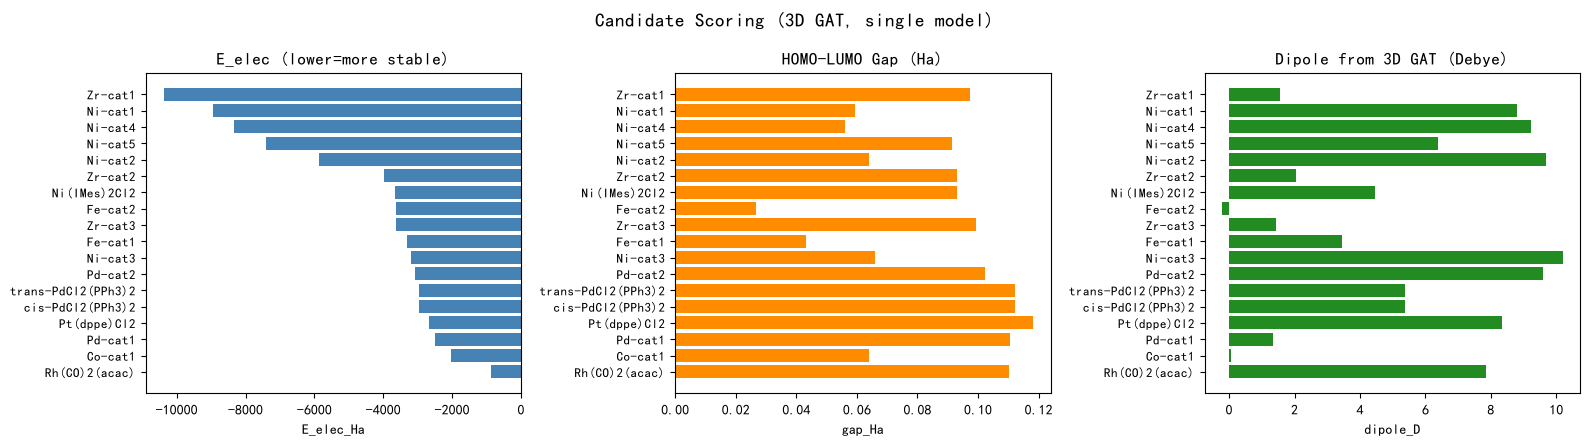

In [5]:
# 可视化排名
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
names = df['Name'].values
for ax, col, title, color in [
    (axes[0], 'E_elec_Ha', 'E_elec (lower=more stable)', 'steelblue'),
    (axes[1], 'gap_Ha', 'HOMO-LUMO Gap (Ha)', 'darkorange'),
    (axes[2], 'dipole_D', 'Dipole from 3D GAT (Debye)', 'forestgreen'),
]:
    ax.barh(range(len(names)), df[col].values, color=color)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel(col)
    ax.set_title(title)
    ax.invert_yaxis()
plt.suptitle('Candidate Scoring (3D GAT, single model)', fontsize=14)
plt.tight_layout(); plt.show()



## 输出说明

| 列 | 来源模型 | 说明 |
|----|---------|------|
| 全部 8 项性质 | **3D GAT** | 单一模型预测所有性质 |
| E_elec_Ha | 3D GAT | 按此项排序, 越低越稳定 |
| dipole_D | 3D GAT | 基于 ETKDG+MMFF 生成坐标的 RBF 距离编码 |
| gap_Ha / homo_Ha / lumo_Ha | 3D GAT | 前线轨道能量 |

> 输入仅需 SMILES 字符串。3D 坐标由 ETKDG 构象搜索 + MMFF 力场优化自动生成。
> Mayer bond orders 在推理时设为 0。
> 使用 12-head GAT x 384d x 5 layers checkpoint。
